<center><h1>Huang_Shane_HW6</h1></center>

Name: Shane Huang
<br>
Github Username: shae513351
<br>
USC ID: 5886395143

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn import set_config
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

### (a) Download the APS Failure data

In [65]:
# Set the directory containing the dataset files.
DATA_DIR = Path("../data")

train_path = DATA_DIR / "aps_failure_training_set.csv"
test_path = DATA_DIR / "aps_failure_test_set.csv"

# Skip the introductory text and interpret "na" as a missing value.
train_df = pd.read_csv(
    train_path,
    skiprows=20,
    na_values=["na"]
)

test_df = pd.read_csv(
    test_path,
    skiprows=20,
    na_values=["na"]
)

# Check the dimensions of the original datasets.
print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)

# Verify that both datasets have the same columns in the same order.
print("Columns match:", train_df.columns.equals(test_df.columns))

# Check the class labels and numeric feature types.
print("Training class labels:", train_df["class"].unique())

non_numeric_features = (
    train_df.drop(columns="class")
    .select_dtypes(exclude="number")
    .columns.tolist()
)
print("Non-numeric feature columns:", non_numeric_features)

# Preview the training data.
#display(train_df.head())

Training set shape: (60000, 171)
Test set shape: (16000, 171)
Columns match: True
Training class labels: <StringArray>
['neg', 'pos']
Length: 2, dtype: str
Non-numeric feature columns: []


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

The imputation methods I found include Univariate feature(mean, median, most-frequent), KNN,
and iterative imputation. I chose median imputation because all predictors are numeric, it is
computationally efficient, and the median is less sensitive to extreme
values than the mean.

Reference:
https://scikit-learn.org/stable/modules/impute.html

In [3]:
# Separate the predictors from the target.
X_train_raw = train_df.drop(columns="class").copy()
X_test_raw = test_df.drop(columns="class").copy()

# Encode the negative class as 0 and the positive class as 1.
y_train = train_df["class"].map({"neg": 0, "pos": 1}).astype(int)
y_test = test_df["class"].map({"neg": 0, "pos": 1}).astype(int)

# Summarize missing values in the training features.
missing_summary = pd.DataFrame({
    "Missing Count": X_train_raw.isna().sum(),
    "Missing Percentage": X_train_raw.isna().mean() * 100
}).sort_values("Missing Count", ascending=False)

display(missing_summary.head(10))

# Check whether any training feature is entirely missing.
all_missing_features = X_train_raw.columns[
    X_train_raw.isna().all()
].tolist()

print("Entirely missing training features:", all_missing_features)

,Missing Count,Missing Percentage
br_000,49264,82.106667
bq_000,48722,81.203333
bp_000,47740,79.566667
bo_000,46333,77.221667
ab_000,46329,77.215000
cr_000,46329,77.215000
bn_000,44009,73.348333
bm_000,39549,65.915000
bl_000,27277,45.461667
bk_000,23034,38.390000


Entirely missing training features: []


In [4]:
# Ensure that every training feature has observed values.
assert not all_missing_features, (
    f"These features have no observed training values: {all_missing_features}"
)

# Learn one median per feature from the training data.
imputer = SimpleImputer(strategy="median")

# Fill missing values while preserving column names and row indices.
X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

# Apply the training medians to the test data.
X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

# Verify the imputed datasets.
print("Training feature shape:", X_train.shape)
print("Test feature shape:", X_test.shape)
print("Remaining training missing values:", X_train.isna().sum().sum())
print("Remaining test missing values:", X_test.isna().sum().sum())

Training feature shape: (60000, 170)
Test feature shape: (16000, 170)
Remaining training missing values: 0
Remaining test missing values: 0


#### (ii) Calculate the coefficient of variation

In [47]:
# Calculate the mean and sample standard deviation of each feature.
feature_means = X_train.mean()
feature_stds = X_train.std(ddof=1)

# Treat CV as undefined when the feature mean is zero.
feature_cv = feature_stds / feature_means.replace(0, np.nan)

# Summarize all 170 features and rank them by CV.
cv_summary = pd.DataFrame({
    "Mean": feature_means,
    "Sample Std": feature_stds,
    "CV": feature_cv
}).sort_values("CV", ascending=False)

# Display all 170 CV values in parallel blocks.
cv_display = cv_summary["CV"].rename_axis("Feature").reset_index()
block_size = int(np.ceil(len(cv_display) / 6))

blocks = [
    cv_display.iloc[start:start + block_size].reset_index(drop=True)
    for start in range(0, len(cv_display), block_size)
]

with pd.option_context("display.max_rows", 30, "display.max_columns", 12):
    display(pd.concat(blocks, axis=1).round(5).fillna(""))

# Check the number of features and any undefined CV values.
print("Number of features:", len(cv_summary))
print("Features with undefined CV:",
      cv_summary.index[cv_summary["CV"].isna()].tolist())

C:\Users\burdi\AppData\Local\Temp\ipykernel_28292\2956478775.py:25: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(pd.concat(blocks, axis=1).round(5).fillna(""))


,Feature,CV,Feature,CV,Feature,CV,Feature,CV,Feature,CV,Feature,CV
0,cf_000,244.88752,ea_000,34.94652,am_0,9.15522,eb_000,4.53989,az_004,2.84899,ah_000,2.31173
1,co_000,244.50739,cn_009,34.27205,az_006,8.88057,de_000,4.52753,ee_005,2.84673,ac_000,2.31024
2,ad_000,244.32282,ay_004,33.75235,ag_003,8.64740,cn_003,4.19216,ba_007,2.84412,bg_000,2.30931
3,cs_009,237.93055,ag_009,33.35757,ct_000,7.84999,cg_000,4.02509,ba_003,2.73265,ce_000,2.27121
4,dh_000,123.21610,da_000,29.36753,dy_000,7.79665,ax_000,4.01905,ba_000,2.69956,ao_000,2.27068
5,dj_000,117.49423,ay_003,28.73509,az_001,7.72087,ay_008,3.81568,ba_005,2.69771,an_000,2.25
6,ag_000,92.91776,cn_000,26.33557,az_003,7.52740,cs_001,3.66305,ba_004,2.63174,dt_000,2.19192
7,as_000,87.33250,ae_000,24.20014,bf_000,7.45354,dv_000,3.58737,bh_000,2.62872,do_000,2.16607
8,ay_009,84.73373,at_000,23.70819,bc_000,7.26445,bj_000,3.57579,ba_001,2.62444,cs_006,2.14264
9,ak_000,80.42498,az_008,22.67965,dr_000,6.86545,ay_007,3.31396,ee_004,2.62169,dp_000,2.02232


Number of features: 170
Features with undefined CV: []


#### (iii) Plot a correlation matrix

Constant features: ['cd_000']


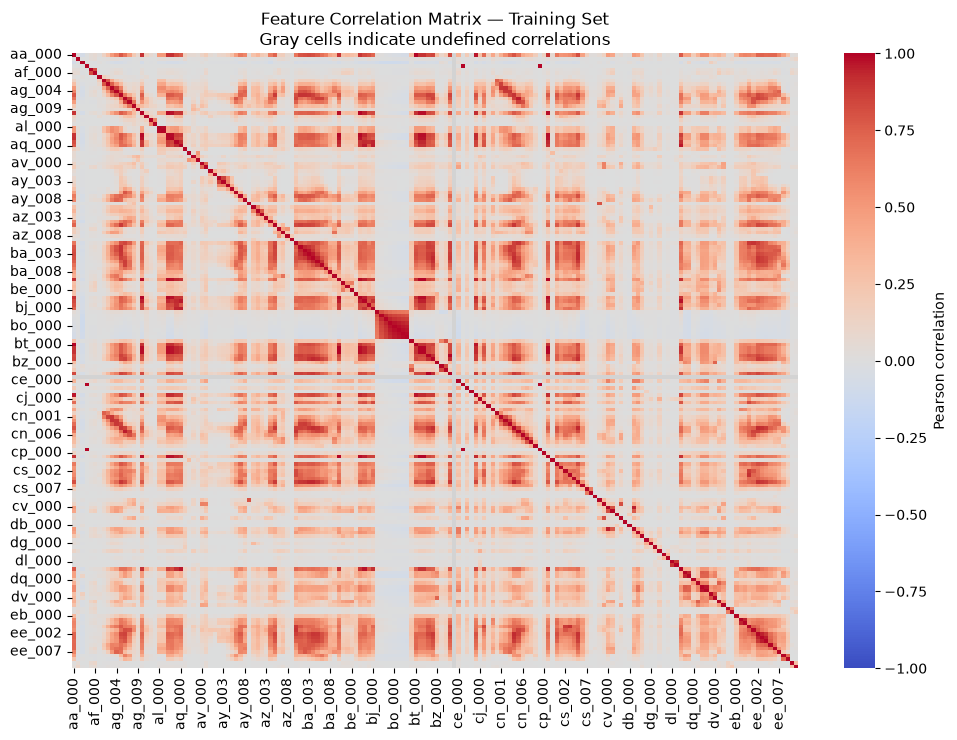

In [48]:
# Calculate Pearson correlations for all 170 training features.
corr_matrix = X_train.corr(method="pearson")

# Identify constant features, whose correlations are undefined.
constant_features = X_train.columns[X_train.nunique() == 1].tolist()
print("Constant features:", constant_features)

# Use gray to distinguish undefined correlations from zero correlations.
cmap = plt.get_cmap("coolwarm").copy()
cmap.set_bad("lightgray")

# Plot the full correlation matrix with fewer tick labels.
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.set_facecolor("lightgray")

sns.heatmap(
    corr_matrix,
    mask=corr_matrix.isna(),
    cmap=cmap,
    vmin=-1,
    vmax=1,
    center=0,
    annot=False,
    xticklabels=5,
    yticklabels=5,
    cbar_kws={"label": "Pearson correlation"},
    ax=ax
)

ax.set_title(
    "Feature Correlation Matrix — Training Set\n"
    "Gray cells indicate undefined correlations"
)
ax.tick_params(axis="x", labelrotation=90)
ax.tick_params(axis="y", labelrotation=0)

plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

In [ ]:
# Select the features with the highest coefficients of variation.
n_selected = int(np.sqrt(X_train.shape[1]))

selected_features = (
    cv_summary["CV"]
    .dropna()
    .head(n_selected)
    .index
    .tolist()
)
print("Number of selected features:", len(selected_features))
display(cv_summary.loc[selected_features])

# Create a separate dataframe for visualization.
plot_df = X_train[selected_features].copy()
plot_df["class"] = y_train.map({0: "neg", 1: "pos"})

Number of selected features: 13


,Mean,Sample Std,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


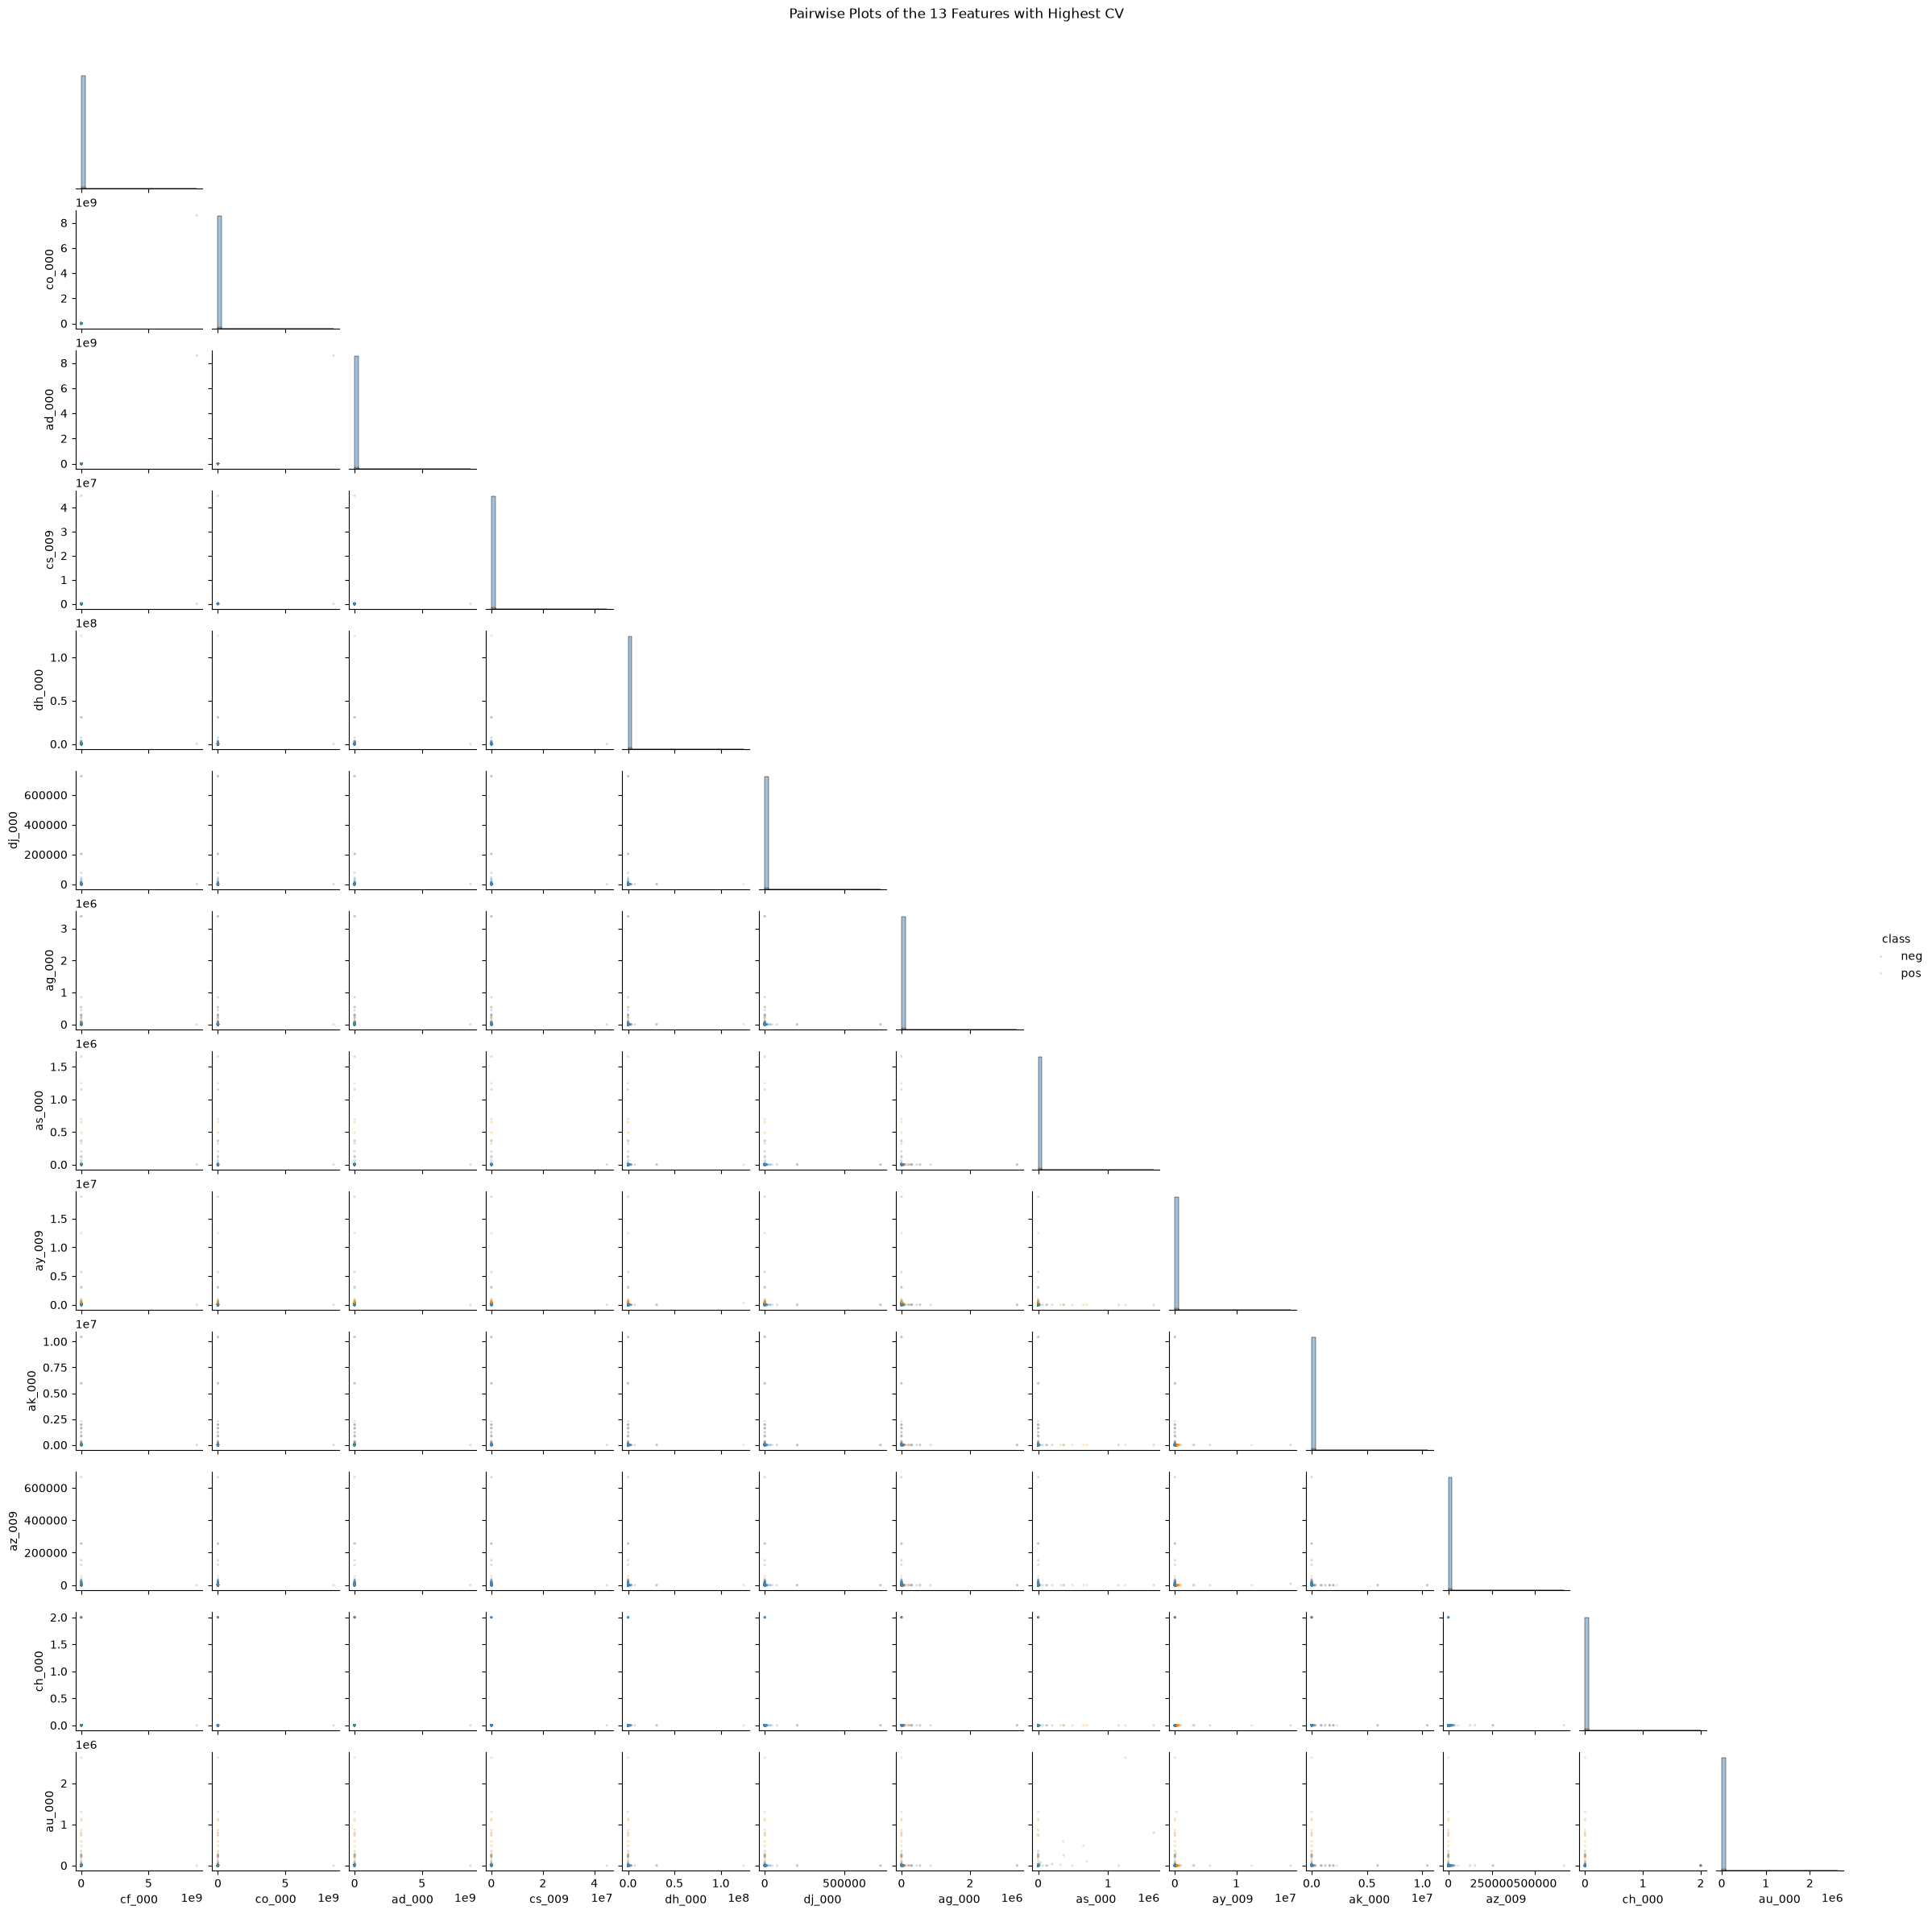

In [8]:
# Plot pairwise relationships using all training observations.
pair_grid = sns.pairplot(
    data=plot_df,
    vars=selected_features,
    hue="class",
    hue_order=["neg", "pos"],
    palette={"neg": "steelblue", "pos": "darkorange"},
    corner=True,
    diag_kind="hist",
    height=1.8,
    plot_kws={
        "s": 5,
        "alpha": 0.25,
        "linewidth": 0,
        "rasterized": True
    },
    diag_kws={"bins": 30}
)

pair_grid.figure.suptitle(
    "Pairwise Plots of the 13 Features with Highest CV",
    y=1.02
)

plt.show()

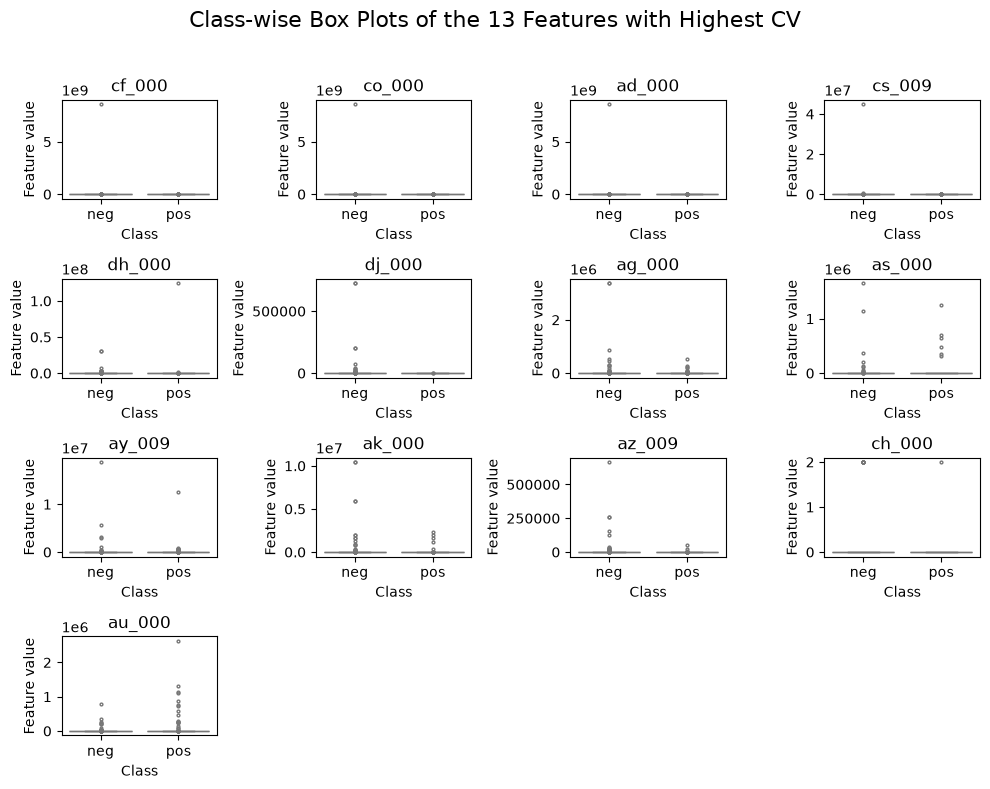

In [ ]:
# Compare the feature distributions between the two classes.
ncols = 4
nrows = int(np.ceil(len(selected_features) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(10, 2 * nrows)
)

axes = axes.ravel()

for ax, feature in zip(axes, selected_features):
    sns.boxplot(
        data=plot_df,
        x="class",
        y=feature,
        order=["neg", "pos"],
        color="lightsteelblue",
        showfliers=True,
        fliersize=2,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xlabel("Class")
    ax.set_ylabel("Feature value")

# Hide unused panels.
for ax in axes[len(selected_features):]:
    ax.set_visible(False)

fig.suptitle(
    "Class-wise Box Plots of the 13 Features with Highest CV",
    fontsize=16
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

No, we can't. Scatter plots alone cannot establish the statistical significance or
predictive importance of these features. A high coefficient of variation
indicates large relative variability, but not necessarily strong predictive
ability. For example, dh_000 and au_000 have very large values in the positive class, but these few extreme observations are insufficient to establish that these features can effectively distinguish between the two classes. It may just be driven by extreme values.

#### (v) Is this data set imbalanced?

In [54]:
# Count each class in the training and test sets.
class_summary = pd.DataFrame({
    "Training Count": train_df["class"].value_counts(),
    "Test Count": test_df["class"].value_counts()
}).reindex(["neg", "pos"])

# Calculate class percentages within each dataset.
class_summary["Training Percentage"] = (
    class_summary["Training Count"] / len(train_df) * 100
)
class_summary["Test Percentage"] = (
    class_summary["Test Count"] / len(test_df) * 100
)

display(class_summary.round(2))

# Calculate the negative-to-positive ratio in the training set.
imbalance_ratio = (
    class_summary.loc["neg", "Training Count"]
    / class_summary.loc["pos", "Training Count"]
)

print(f"Training negative-to-positive ratio: {imbalance_ratio:.0f}:1")

,Training Count,Test Count,Training Percentage,Test Percentage
class,,,,
neg,59000,15625,98.33,97.66
pos,1000,375,1.67,2.34


Training negative-to-positive ratio: 59:1


The training set contains 59,000 negative observations (98.33%) and
1,000 positive observations (1.67%), giving a negative-to-positive ratio
of 59:1. Therefore, the dataset is severely imbalanced.

### (c) Train a random forest

In [55]:
# Define a function to reduce redundant code in 1(c) ~ 1(f)
def evaluate_model(model, Xtr, Xte, name, estimate=None, estimate_name=None):
    """Evaluate original train/test observations and plot required results."""
    fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.1))
    rows = {}

    for ax, (split, X, y) in zip(
        axes[:2], [("Train", Xtr, y_train), ("Test", Xte, y_test)]
    ):
        pred = model.predict(X)
        pos_index = list(model.classes_).index(1)
        prob = model.predict_proba(X)[:, pos_index]
        cm = confusion_matrix(y, pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()

        rows[split] = {
            "Error": 1 - accuracy_score(y, pred),
            "AUC": roc_auc_score(y, prob),
            "FP": fp, "FN": fn, "Recall": tp / (tp + fn)
        }
        ConfusionMatrixDisplay(cm, display_labels=["neg", "pos"]).plot(
            ax=ax, cmap="Blues", values_format="d", colorbar=False
        )
        ax.set_title(split, fontsize=10)
        ax.set_xlabel("Predicted", fontsize=9)
        ax.set_ylabel("Actual", fontsize=9)

        fpr, tpr, _ = roc_curve(y, prob)
        axes[2].plot(
            fpr, tpr, label=f"{split}: AUC={rows[split]['AUC']:.4f}"
        )

    axes[2].plot([0, 1], [0, 1], "--", color="gray")
    axes[2].set(
        title="ROC", xlabel="False positive rate", ylabel="True positive rate"
    )
    axes[2].legend(fontsize=8, loc="lower right")
    fig.suptitle(name, fontsize=11)
    fig.tight_layout()
    plt.show()

    result = pd.DataFrame(rows).T
    display(result.round(6))
    if estimate is not None:
        gap = result.loc["Test", "Error"] - estimate
        print(f"{estimate_name} error={estimate:.6f}; Test−estimate={gap:.6f}")
    return result

In [56]:
# Train a random forest without class imbalance compensation.
rf = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

# Use all 170 median-imputed features.
rf.fit(X_train, y_train);

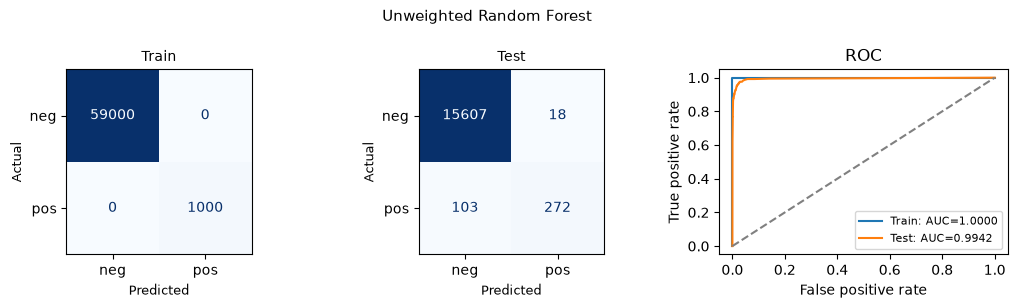

,Error,AUC,FP,FN,Recall
Train,0.000000,1.000000,0.0,0.0,1.000000
Test,0.007563,0.994226,18.0,103.0,0.725333


OOB error=0.005733; Test−estimate=0.001829


In [57]:
# Evaluate the unweighted random forest.
rf_eval = evaluate_model(
    rf, X_train, X_test, "Unweighted Random Forest",
    estimate=1 - rf.oob_score_, estimate_name="OOB"
)

### (d) Research class imbalance in random forest

Common approaches to class imbalance in random forests include class
weighting, majority-class undersampling, and minority-class oversampling. I chose class weighting because it retains all training observations while increasing the influence of the minority class.

Reference:
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

In [58]:
# Tried calss_weight= "balance", 
# Apply class weights calculated separately within each bootstrap sample.
rf_balanced = clone(rf).set_params(
    class_weight="balanced_subsample"
)

rf_balanced.fit(X_train, y_train);

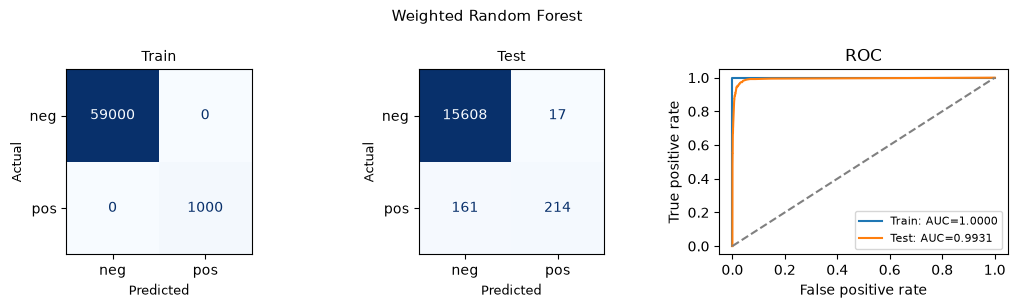

,Error,AUC,FP,FN,Recall
Train,0.000000,1.000000,0.0,0.0,1.000000
Test,0.011125,0.993133,17.0,161.0,0.570667


OOB error=0.007567; Test−estimate=0.003558


In [59]:
# Evaluate the weighted random forest.
rf_bal_eval = evaluate_model(
    rf_balanced, X_train, X_test, "Weighted Random Forest",
    estimate=1 - rf_balanced.oob_score_, estimate_name="OOB"
)

In [60]:
# Compare test metrics for the two random forests.
display(pd.DataFrame({
    "Unweighted RF": rf_eval.loc["Test"],
    "Weighted RF": rf_bal_eval.loc["Test"]
}).round(6))

,Unweighted RF,Weighted RF
Error,0.007563,0.011125
AUC,0.994226,0.993133
FP,18.000000,17.000000
FN,103.000000,161.000000
Recall,0.725333,0.570667


Using class_weight="balanced_subsample" did not improve test performance
under the chosen model settings. Compared with the unweighted model, test error increased from 0.007563
to 0.011125, while test AUC decreased from 0.994226 to 0.993133.
False positives decreased slightly from 18 to 17, but false negatives
increased from 103 to 161. Consequently, positive-class recall fell
from 72.53% to 57.07%. Increasing minority-class training weights does not
guarantee higher recall.

The weighted model's OOB error was 0.007567, compared with a test error
of 0.011125. The OOB estimate underestimated the test error by
approximately 0.003558, or 0.3558 percentage points.

### (e) XGBoost and Model Trees

In [ ]:
# Use text instead of HTML diagrams to display estimators. Prevent unicode error
set_config(display="text")

# Preserve class proportions in each validation fold.
cv5 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Fit the imputer separately within each training fold.
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        booster="gbtree",
        tree_method="hist",
        n_estimators=300,
        max_depth=3,
        learning_rate=0.1,
        reg_lambda=1,
        scale_pos_weight=1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=4
    ))
])

# Search over L1 regularization strengths.
alpha_grid = {
    "xgb__reg_alpha": [0, 0.01, 0.1, 1, 10, 100]
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=alpha_grid,
    scoring={
        "accuracy": "accuracy",
        "recall": "recall",
        "f1": "f1"
    },
    refit="accuracy",
    cv=cv5,
    n_jobs=1,
    verbose=0, #set to 0 to clear unnecessary output
    error_score="raise"
)

# Start from the original features, before imputation.
xgb_search.fit(X_train_raw, y_train);

In [32]:
# Summarize validation performance for every alpha.
cv_results = pd.DataFrame(xgb_search.cv_results_)

xgb_cv_summary = pd.DataFrame({
    "Alpha": cv_results["param_xgb__reg_alpha"].astype(float),
    "Mean CV Error": 1 - cv_results["mean_test_accuracy"],
    "CV Error Std": cv_results["std_test_accuracy"],
    "Mean CV Recall": cv_results["mean_test_recall"],
    "Mean CV F1": cv_results["mean_test_f1"]
}).sort_values("Alpha")

display(xgb_cv_summary.round(6))

# GridSearchCV has already refitted this pipeline on all training data.
best_xgb = xgb_search.best_estimator_
best_alpha = xgb_search.best_params_["xgb__reg_alpha"]
xgb_cv_error = 1 - xgb_search.best_score_

print("Selected alpha:", best_alpha)
print(f"Selected model's mean CV error: {xgb_cv_error:.6f}")

,Alpha,Mean CV Error,CV Error Std,Mean CV Recall,Mean CV F1
0,0.00,0.006050,0.000437,0.744,0.803597
1,0.01,0.005867,0.000417,0.748,0.809330
2,0.10,0.005800,0.000598,0.752,0.811870
3,1.00,0.005967,0.000386,0.745,0.806084
4,10.00,0.007350,0.000867,0.690,0.757238
5,100.00,0.011350,0.000710,0.474,0.581962


Selected alpha: 0.1
Selected model's mean CV error: 0.005800


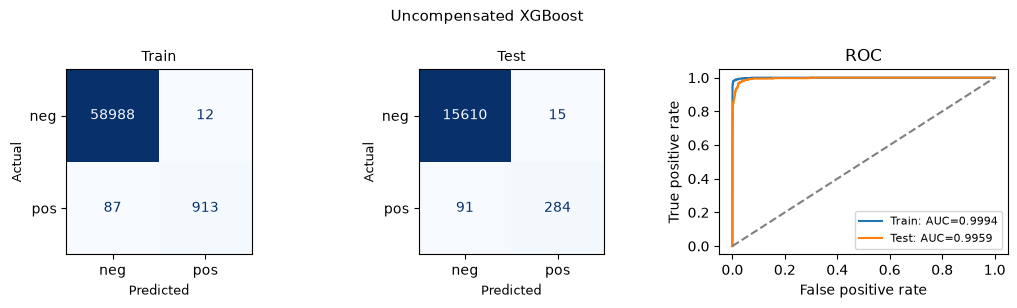

,Error,AUC,FP,FN,Recall
Train,0.001650,0.999416,12.0,87.0,0.913000
Test,0.006625,0.995910,15.0,91.0,0.757333


CV error=0.005800; Test−estimate=0.000825


In [61]:
# Evaluate the fitted XGBoost pipeline on raw features.
xgb_eval = evaluate_model(
    best_xgb, X_train_raw, X_test_raw, "Uncompensated XGBoost",
    estimate=xgb_cv_error, estimate_name="CV"
)

### (f) Use SMOTE to pre-process your data

In [35]:
# %pip install imbalanced-learn
# Keep the XGBoost settings from 1(e).
# GridSearchCV will search reg_alpha again.
smote_xgb_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(
        sampling_strategy=1.0,
        k_neighbors=5,
        random_state=42
    )),
    ("xgb", clone(xgb_pipeline.named_steps["xgb"]))
])

# Use the same alpha grid, folds, and selection criterion as in 1(e).
smote_search = GridSearchCV(
    estimator=smote_xgb_pipeline,
    param_grid=alpha_grid,
    scoring={
        "accuracy": "accuracy",
        "recall": "recall",
        "f1": "f1"
    },
    refit="accuracy",
    cv=cv5,
    n_jobs=1,
    verbose=0, 
    error_score="raise"
)

# Apply preprocessing and SMOTE within each training fold.
smote_search.fit(X_train_raw, y_train);

In [26]:
# Summarize validation performance for each alpha.
smote_cv_results = pd.DataFrame(smote_search.cv_results_)

smote_cv_summary = pd.DataFrame({
    "Alpha": smote_cv_results["param_xgb__reg_alpha"].astype(float),
    "Mean CV Error": 1 - smote_cv_results["mean_test_accuracy"],
    "CV Error Std": smote_cv_results["std_test_accuracy"],
    "Mean CV Recall": smote_cv_results["mean_test_recall"],
    "Mean CV F1": smote_cv_results["mean_test_f1"]
}).sort_values("Alpha")

display(smote_cv_summary.round(6))

# Retrieve the pipeline refitted on the full training set.
best_smote_xgb = smote_search.best_estimator_
smote_best_alpha = smote_search.best_params_["xgb__reg_alpha"]
smote_cv_error = 1 - smote_search.best_score_

print("Selected alpha:", smote_best_alpha)
print(f"Selected model's mean CV error: {smote_cv_error:.6f}")

# Report how many synthetic observations were added during final refitting.
print(
    "Synthetic observations added:",
    best_smote_xgb.named_steps["smote"].sampling_strategy_
)

,Alpha,Mean CV Error,CV Error Std,Mean CV Recall,Mean CV F1
0,0.00,0.010950,0.000752,0.837,0.718075
1,0.01,0.010900,0.000954,0.833,0.718290
2,0.10,0.010717,0.000581,0.842,0.723714
3,1.00,0.010850,0.000616,0.849,0.722928
4,10.00,0.011767,0.001040,0.843,0.705105
5,100.00,0.021050,0.000895,0.891,0.585260


Selected alpha: 0.1
Selected model's mean CV error: 0.010717
Synthetic observations added: OrderedDict({np.int64(1): 58000})


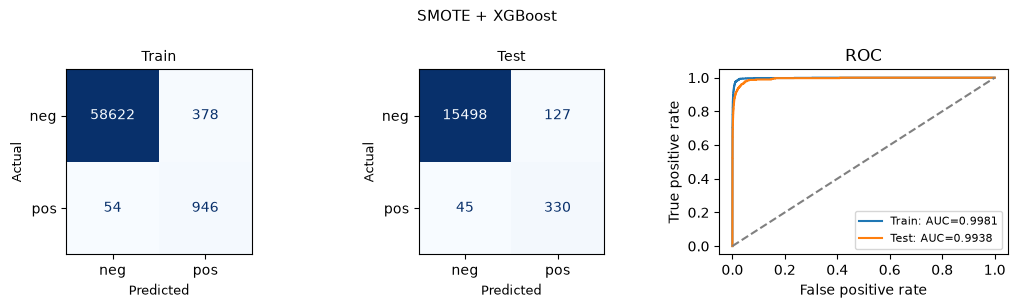

,Error,AUC,FP,FN,Recall
Train,0.00720,0.998098,378.0,54.0,0.946
Test,0.01075,0.993837,127.0,45.0,0.880


CV error=0.010717; Test−estimate=0.000033


In [62]:
# Evaluate original observations; SMOTE is skipped during prediction.
smote_eval = evaluate_model(
    best_smote_xgb, X_train_raw, X_test_raw, "SMOTE + XGBoost",
    estimate=smote_cv_error, estimate_name="CV"
)

In [63]:
# Compare test metrics for the two XGBoost pipelines.
display(pd.DataFrame({
    "Uncompensated XGB": xgb_eval.loc["Test"],
    "SMOTE + XGB": smote_eval.loc["Test"]
}).round(6))

,Uncompensated XGB,SMOTE + XGB
Error,0.006625,0.010750
AUC,0.995910,0.993837
FP,15.000000,127.000000
FN,91.000000,45.000000
Recall,0.757333,0.880000


## 2. ISLR 6.6.3

(a) iv. Training RSS decreases or remains constant as s increases.
A larger s expands the feasible set of coefficients, so the minimum
training RSS cannot increase. Once the constraint becomes inactive,
the fit reaches the least-squares solution and training RSS levels off.

(b) ii. Test RSS is expected to decrease initially and then increase.
Relaxing a strong constraint initially reduces underfitting and bias.
With further increases in flexibility, increased variance can worsen
test performance, producing a typical U-shaped curve.

(c) iii. Variance generally increases because a more flexible model
is more sensitive to changes in the training data.

(d) iv. Squared bias generally decreases because relaxing the
constraint allows the model to better approximate the true relationship.

(e) v. The irreducible error remains constant because it reflects
inherent randomness in the data-generating process and does not
depend on s.

## 3. ISLR 6.6.5

(a) Since the predictors are identical and the intercept is zero,
the ridge optimization problem is

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}
[y_i-x_i(\beta_1+\beta_2)]^2
+\lambda(\beta_1^2+\beta_2^2),
$$

where $x_i=x_{i1}=x_{i2}$ and $\lambda>0$.

(b) For a fixed sum $t=\beta_1+\beta_2$, the RSS is unchanged.
Furthermore,

$$
\beta_1^2+\beta_2^2
=\frac{t^2}{2}+\frac{(\beta_1-\beta_2)^2}{2}.
$$

The penalty is minimized when $\beta_1=\beta_2$. Therefore,
the ridge estimates satisfy $\hat\beta_1=\hat\beta_2$.

(c) The lasso optimization problem is

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}
[y_i-x_i(\beta_1+\beta_2)]^2
+\lambda(|\beta_1|+|\beta_2|).
$$

(d) Both predictions and RSS depend only on the coefficient sum.
By the triangle inequality,

$$
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|,
$$

with equality when the coefficients have the same sign or one is zero.
Thus, if the optimal sum $\hat t$ is nonzero, every pair

$$
(\hat\beta_1,\hat\beta_2)
=(a\hat t,(1-a)\hat t),\qquad 0\leq a\leq1,
$$

has the same minimum objective value. Hence, the individual lasso
coefficients are not unique.

If the optimal sum is zero, however, the unique solution for
$\lambda>0$ is $(0,0)$.

## 4. ISLR 8.4.5

Under majority voting, six trees predict Red because their estimated
probabilities exceed 0.5, while four trees predict Green. Therefore,
the final classification is Red.

Under probability averaging, the mean estimated probability of Red is

$$
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=0.45.
$$

Since 0.45 is below 0.5, the final classification is Green.

The predictions differ because majority voting uses only each tree's
predicted class, whereas probability averaging also accounts for the
magnitude of each estimated probability.

## 5. ISLR 9.7.3

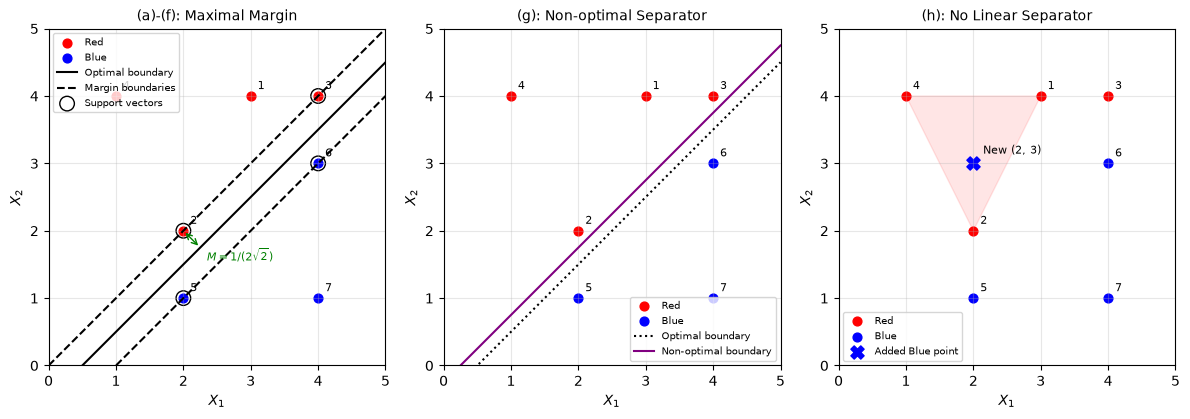

In [64]:
# Define observations and support vectors (zero-based indices).
toy_X = np.array([[3, 4], [2, 2], [4, 4], [1, 4],
                  [2, 1], [4, 3], [4, 1]])
support_indices = [1, 2, 4, 5]
line_x = np.linspace(0, 5, 200)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

# Draw the original observations and labels in each panel.
for ax in axes:
    ax.scatter(toy_X[:4, 0], toy_X[:4, 1], c="red", s=40, label="Red")
    ax.scatter(toy_X[4:, 0], toy_X[4:, 1], c="blue", s=40, label="Blue")
    for obs_id, (x1, x2) in enumerate(toy_X, start=1):
        ax.annotate(str(obs_id), (x1, x2), xytext=(5, 5),
                    textcoords="offset points", fontsize=8)
    ax.set(xlabel="$X_1$", ylabel="$X_2$", xlim=(0, 5), ylim=(0, 5))
    ax.set_aspect("equal")
    ax.grid(alpha=0.3)

# (a)-(f): Optimal boundary, margin boundaries, and support vectors.
ax = axes[0]
ax.plot(line_x, line_x - 0.5, "k-", label="Optimal boundary")
ax.plot(line_x, line_x, "k--", label="Margin boundaries")
ax.plot(line_x, line_x - 1, "k--")
ax.scatter(toy_X[support_indices, 0], toy_X[support_indices, 1],
           s=110, facecolors="none", edgecolors="black", label="Support vectors")
ax.annotate("", xy=(2.25, 1.75), xytext=(2, 2),
            arrowprops={"arrowstyle": "<->", "color": "green"})
ax.text(2.35, 1.55, r"$M=1/(2\sqrt{2})$", color="green", fontsize=8)
ax.set_title("(a)-(f): Maximal Margin", fontsize=10)

# (g): A valid separating line with a smaller margin.
ax = axes[1]
ax.plot(line_x, line_x - 0.5, "k:", label="Optimal boundary")
ax.plot(line_x, line_x - 0.25, color="purple", label="Non-optimal boundary")
ax.set_title("(g): Non-optimal Separator", fontsize=10)

# (h): Add a Blue point inside the triangle of Red observations 1, 2, 4.
ax = axes[2]
triangle = toy_X[[0, 1, 3]]
ax.fill(triangle[:, 0], triangle[:, 1], color="red", alpha=0.1)
ax.scatter(2, 3, c="blue", marker="X", s=90, label="Added Blue point")
ax.annotate("New (2, 3)", (2, 3), xytext=(7, 7),
            textcoords="offset points", fontsize=8)
ax.set_title("(h): No Linear Separator", fontsize=10)

for ax in axes:
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

(a) The seven observations are shown in the plot.

(b) The optimal separating hyperplane is

$$
0.5-X_1+X_2=0.
$$

It lies halfway between the parallel supporting lines
$X_2=X_1$ and $X_2=X_1-1$.

(c) Classify an observation as Red if $0.5-X_1+X_2>0$,
and Blue otherwise. Thus, one valid coefficient representation is
$\beta_0=0.5$, $\beta_1=-1$, and $\beta_2=1$.

(d) The margin is the perpendicular distance from the separating
hyperplane to either supporting line:

$$
M=\frac{0.5}{\sqrt{(-1)^2+1^2}}
=\frac{1}{2\sqrt{2}}\approx0.3536.
$$

The total width between the supporting lines is $2M\approx0.7071$.

(e) The support vectors are observations 2, 3, 5, and 6.

(f) Observation 7 lies strictly beyond the Blue margin boundary.
A sufficiently small movement that keeps it beyond this boundary
does not change the maximal margin hyperplane.

(g) One non-optimal separating hyperplane is

$$
0.25-X_1+X_2=0.
$$

It correctly separates all seven observations but has a smaller
minimum distance to the observations than the optimal hyperplane.

(h) Add a Blue observation at $(2,3)$. This point lies inside the
triangle formed by Red observations 1, 2, and 4, since

$$
(2,3)=0.25(3,4)+0.5(2,2)+0.25(1,4).
$$

Therefore, no hyperplane can separate all Red observations from
all Blue observations.